# 01 · Source profiling: Natural Disaster Insurance Data Warehouse

**Purpose.** Profile all four raw sources *before* any transformation, as Task 3 of the brief requires. Every number here is evidence for the data-quality log (`docs/03_data_quality_log.md`) and for the source mapping (`docs/02_source_mapping.md`).

**What this notebook answers**

| Section | Question it answers |
|---|---|
| 1. Raw file structure | Where does the real header start, and what junk surrounds the data? |
| 2. ICA catastrophe list | What is the grain, which keys are usable, and how clean are the dates, states, losses and claims? |
| 3. Disaster events | What period does it cover, how are dates written, and how complete are the impact columns? |
| 4. ABS population and income | Which geography levels and years are present, and where are the values missing? |
| 5. Cross-source integration | Can the sources be matched at all: on state, hazard, time and event? Do they agree when they overlap? |
| 6. Data-quality summary | One table of every issue with its evidence count, ready for the report |

**How to run.** In Databricks, the four CSVs must be in the volume `/Volumes/workspace/raw/files/` named `ica.csv`, `disaster_events.csv`, `abs_population.csv` and `abs_income.csv`. Locally, put them in `./data/raw/`. Then run all cells. Nothing is modified: every file is read as text.

**Evidence.** Set `SAVE_EVIDENCE = True` to write every summary table (CSV) and chart (PNG) to `evidence/profiling/` for screenshots and the report.

In [1]:
import os, re, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATA_DIR = "/Volumes/workspace/raw/files" if os.path.exists("/Volumes/workspace/raw/files") else "./data/raw"
FILES = {"ica": "ica.csv", "de": "disaster_events.csv", "pop": "abs_population.csv", "inc": "abs_income.csv"}
SAVE_EVIDENCE = True
EVIDENCE_DIR = "./evidence/profiling"
SCOPE_START_YEAR = 2011          # warehouse scope agreed in P1
CURRENT_YEAR = pd.Timestamp.today().year

pd.set_option("display.max_columns", 50, "display.max_colwidth", 80, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
if SAVE_EVIDENCE:
    os.makedirs(EVIDENCE_DIR, exist_ok=True)
print("Reading from:", os.path.abspath(DATA_DIR))

Reading from: /home/claude/prof/data/raw


### Helper functions
Small reusable tools, so every source is profiled the same way.

- `to_num` turns text like `"$48,957,139"` into a number. It reports what failed rather than hiding it.
- `signature` replaces digits with `9` and letters with `A`, so `"4-Mar-26"` becomes `"9-Aaa-99"`. Counting signatures reveals every format a column uses.
- `profile` builds one row per column: fill rate, placeholders, distinct values, top values, dominant formats, and how much of it parses as a number or date.

In [2]:
PLACEHOLDERS = {"-", "--", "#REF!", "n/a", "N/A", "NA", "na", "..", "np", "null", "NULL", "None"}

def to_num(s, dash_as_zero=False):
    """Text -> float. Strips $, commas and spaces. '-' becomes 0 or NaN depending on the source's convention."""
    t = s.astype(str).str.strip().str.replace(r"[\$,\s]", "", regex=True)
    if dash_as_zero:
        t = t.replace({"-": "0"})
    return pd.to_numeric(t.replace({"": np.nan}), errors="coerce")

def signature(v):
    v = str(v)
    if v.strip() == "":
        return "<blank>"
    v = re.sub(r"\d", "9", v)
    v = re.sub(r"[A-Z]", "A", v)
    v = re.sub(r"[a-z]", "a", v)
    return v if len(v) <= 30 else v[:30] + "…"

def try_dates(s, formats):
    """Return (parsed series, which format matched) trying each format in order."""
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    used = pd.Series(None, index=s.index, dtype="object")
    for f in formats:
        p = pd.to_datetime(s.where(out.isna()), format=f, errors="coerce")
        hit = p.notna() & out.isna()
        out[hit], used[hit] = p[hit], f
    return out, used

def profile(df, name):
    rows = []
    n = len(df)
    for c in df.columns:
        s = df[c].astype(str)
        st = s.str.strip()
        blank = (st == "").sum()
        ph = st.isin(PLACEHOLDERS).sum()
        filled = st[(st != "") & ~st.isin(PLACEHOLDERS)]
        vc = filled.value_counts()
        num_rate = to_num(filled).notna().mean() if len(filled) else np.nan
        sigs = filled.map(signature).value_counts()
        rows.append({
            "column": c,
            "filled_%": round(100 * len(filled) / n, 1) if n else np.nan,
            "blank": blank, "placeholder": ph,
            "distinct": filled.nunique(),
            "unique?": "yes" if len(filled) and filled.nunique() == len(filled) else "",
            "numeric_%": round(100 * num_rate, 1) if pd.notna(num_rate) else np.nan,
            "formats": len(sigs),
            "top_format": sigs.index[0] if len(sigs) else "",
            "top_values": "; ".join(f"{k[:25]} ({v})" for k, v in vc.head(3).items()),
        })
    out = pd.DataFrame(rows)
    save(out, f"{name}_column_profile")
    return out

def save(df, name):
    if SAVE_EVIDENCE:
        df.to_csv(f"{EVIDENCE_DIR}/{name}.csv", index=False)

def savefig(name):
    plt.tight_layout()
    if SAVE_EVIDENCE:
        plt.savefig(f"{EVIDENCE_DIR}/{name}.png", bbox_inches="tight")
    plt.show()

def finding(text):
    display(Markdown(f"> **Finding:** {text}"))

DQ = []   # collected issues -> Section 6
def log_issue(dq_id, source, column, dimension, issue, affected, total, example, rule):
    DQ.append(dict(id=dq_id, source=source, column=column, dimension=dimension, issue=issue,
                   affected=int(affected), total=int(total),
                   pct=round(100 * affected / total, 1) if total else np.nan,
                   example=str(example)[:80], proposed_rule=rule))

## 1. Raw file structure
Before choosing `skiprows`, look at the first and last raw lines of each file. Statistical-agency CSVs often have title rows above the header and notes or copyright lines below the data. Those must not be loaded as data.

In [3]:
def raw_lines(path, n=8):
    with open(path, encoding="utf-8-sig", errors="replace") as f:
        lines = f.read().splitlines()
    return lines

structure = []
for key, fname in FILES.items():
    lines = raw_lines(f"{DATA_DIR}/{fname}")
    print(f"\n=== {fname}: {len(lines):,} raw lines ===")
    for i, line in enumerate(lines[:8]):
        print(f"  {i:>2} | {line[:110]}")
    print("   ...")
    for i, line in list(enumerate(lines))[-4:]:
        print(f"  {i:>2} | {line[:110]}")
    structure.append({"file": fname, "raw_lines": len(lines)})


=== ica.csv: 751 raw lines ===
   0 | ,,,,,,,,,,,,,,,,,,,,,,
   1 | ,,,,,,,,,,,,,,,,,,,,,,
   2 | ,,,,,,,,,,,,,,,,,,,,,,
   3 | CAT Name,Event Name,Event Start,Event Finish,Financial Year,State,Town,Description,Type,Year,Postcode,ORIGINAL
   4 | SE264,Queensland flooding,4-Mar-26,13-Mar-26,FY25,QLD,"Queensland flooding, including the Bundaberg region and
   5 | SE263,Northern Territory flooding,4-Mar-26,13-Mar-26,FY25,NT,"Northern Territory flooding, including Katherine
   6 | SE262,Middle East Conflict,28-Feb-26,16-Mar-26,FY25,Outside Australia,Outside Australia,"Travel insurers have 
   7 | CAT261,Victorian Bushfires,7-Jan-26,8-Feb-26,FY25,VIC,Victoria,The Insurance Council of Australia (ICA) has to
   ...
  747 | CAT672,Bushfire,7-Feb-67,7-Feb-67,FY66,,,"An event which became known as the Black Tuesday bushfires. Reported
  748 | CAT671,Cyclone DINAH,22-Jan-67,31-Jan-67,FY66,FNQ,"Bundaberg, Maryborough, Sunshine Coast, Gold Coast, Bli Bli
  749 | Undeclared,Cyclone ELSIE,16-Jan-67,

**Header rows chosen from the output above:** ICA has 3 empty rows before the header. The ABS files have 6 metadata rows (title, release date, table name and two `#REF!` error rows in population) before `Code, Label, Year`. Disaster events starts with its header.

In [4]:
SKIP = {"ica": 3, "de": 0, "pop": 6, "inc": 6}

def load(key):
    path = f"{DATA_DIR}/{FILES[key]}"
    df = pd.read_csv(path, skiprows=SKIP[key], dtype=str, keep_default_na=False,
                     encoding="utf-8-sig", low_memory=False)
    df.columns = [c.strip() for c in df.columns]
    return df

ica, de, pop, inc = (load(k) for k in ["ica", "de", "pop", "inc"])

def overview(df, name, fname):
    st = df.apply(lambda c: c.astype(str).str.strip())
    blank_rows = (st == "").all(axis=1).sum()
    dup_cols = [c for c in df.columns if re.search(r"\.\d+$", c)]
    return {"source": name, "file": fname, "rows": len(df), "columns": df.shape[1],
            "fully_blank_rows": blank_rows,
            "exact_duplicate_rows": df.duplicated().sum(),
            "duplicate_header_names": len(dup_cols)}

ov = pd.DataFrame([overview(ica, "ICA catastrophes", FILES["ica"]),
                   overview(de, "Disaster events", FILES["de"]),
                   overview(pop, "ABS population", FILES["pop"]),
                   overview(inc, "ABS income", FILES["inc"])])
save(ov, "00_overview")
display(ov)

,source,file,rows,columns,fully_blank_rows,exact_duplicate_rows,duplicate_header_names
0,ICA catastrophes,ica.csv,747,23,0,0,0
1,Disaster events,disaster_events.csv,673,43,0,0,0
2,ABS population,abs_population.csv,26188,164,4,3,0
3,ABS income,abs_income.csv,32006,93,4,3,6


## 2. ICA catastrophe list (the client's claims feed)

### 2.1 Column profile
One row per column. Read it left to right: how full is it, are there placeholders, how many distinct values, is it unique (a candidate key), does it look numeric, and how many different *formats* does it use. More than one format in a date or money column is a warning sign.

In [5]:
ica_prof = profile(ica, "ica")
display(ica_prof)

,column,filled_%,blank,placeholder,distinct,unique?,numeric_%,formats,top_format,top_values
0,CAT Name,100.0,0,0,251,,0.0,5,Aaaaaaaaaa,Undeclared (497); SE264 (1); SE263 (1)
1,Event Name,100.0,0,0,628,,0.0,200,Aaaaaaa AAAAA,"East Coast Low (11); Flood, Storm (6); Storm (5)"
2,Event Start,100.0,0,0,710,,0.0,2,99-Aaa-99,18-Mar-90 (4); 16-Feb-83 (3); 13-Mar-67 (3)
3,Event Finish,99.7,2,0,707,,0.0,2,99-Aaa-99,19-Mar-90 (3); 16-Feb-83 (3); 13-Mar-26 (2)
4,Financial Year,100.0,0,0,60,,0.0,1,AA99,FY15 (20); FY96 (19); FY10 (18)
5,State,31.2,514,0,16,,0.0,8,AAA,FNQ (167); SEQ (40); NSW (5)
6,Town,8.2,686,0,59,,0.0,43,Aaaaaa,"Queensland and New South (2); Sydney Region (2); Queensland flooding, incl (1)"
7,Description,100.0,0,0,654,,0.5,531,Aaaaaaaa Aaaaaaa aaaaaaaa 9 aa…,"Indian Ocean, no Australi (12); An Indian Ocean event wit (8); Indian ocean,..."
8,Type,100.0,0,0,7,,0.0,6,Aaaaaaa,Cyclone (458); Storm (116); Flood (66)
9,Year,100.0,0,0,60,,100.0,1,9999,2016 (23); 1996 (22); 2011 (21)


### 2.2 Grain and keys
The warehouse grain is one row per event, so we need a column (or combination) that uniquely identifies an event.

In [6]:
cat = ica["CAT Name"].str.strip()
undeclared = (cat.str.lower() == "undeclared").sum()
declared_unique = cat[cat.str.lower() != "undeclared"].is_unique
dup_name_start = ica.duplicated(["Event Name", "Event Start"], keep=False)

keys = pd.DataFrame([
    {"candidate key": "CAT Name", "distinct": cat.nunique(), "rows": len(ica),
     "unique?": cat.is_unique, "note": f"{undeclared} rows share the value 'Undeclared'"},
    {"candidate key": "CAT Name (declared events only)", "distinct": cat[cat.str.lower() != "undeclared"].nunique(),
     "rows": (cat.str.lower() != "undeclared").sum(), "unique?": declared_unique, "note": "unique only among declared events"},
    {"candidate key": "Event Name + Event Start", "distinct": len(ica) - ica.duplicated(["Event Name", "Event Start"]).sum(),
     "rows": len(ica), "unique?": not dup_name_start.any(), "note": f"{dup_name_start.sum()} rows involved in collisions"},
    {"candidate key": "row number (source position)", "distinct": len(ica), "rows": len(ica), "unique?": True,
     "note": "always unique; used as the event business key in staging"},
])
save(keys, "ica_candidate_keys")
display(keys)
display(ica.loc[dup_name_start, ["CAT Name", "Event Name", "Event Start", "State", "ORIGINAL LOSS VALUE"]])

if dup_name_start.any():
    log_issue("DQ15", "ICA", "Event Name + Event Start", "Uniqueness", "Same event listed twice with different attributes",
              dup_name_start.sum() // 2, len(ica), ica.loc[dup_name_start, "Event Name"].iloc[0],
              "Collapse to one row (keep the row with more filled fields); reject the other with reason 'duplicate'")
finding(f"`CAT Name` is **not** a usable key: {undeclared} of {len(ica)} rows ({undeclared/len(ica):.0%}) are 'Undeclared'. "
        "Grouping by it would merge hundreds of unrelated events into one. The source row number is the only reliable event key.")
log_issue("DQ4", "ICA", "CAT Name", "Uniqueness", "Undeclared events share one code", undeclared, len(ica),
          "CAT Name = 'Undeclared'", "Key events on source row number; keep CAT code as an attribute with declaration_status")

,candidate key,distinct,rows,unique?,note
0,CAT Name,251,747,False,497 rows share the value 'Undeclared'
1,CAT Name (declared events only),250,250,True,unique only among declared events
2,Event Name + Event Start,746,747,False,2 rows involved in collisions
3,row number (source position),747,747,True,always unique; used as the event business key in staging


,CAT Name,Event Name,Event Start,State,ORIGINAL LOSS VALUE
681,Undeclared,Kin Kin Tornado,14-Aug-71,,"$250,000"
682,Undeclared,Kin Kin Tornado,14-Aug-71,FNQ,"$250,000"


> **Finding:** `CAT Name` is **not** a usable key: 497 of 747 rows (67%) are 'Undeclared'. Grouping by it would merge hundreds of unrelated events into one. The source row number is the only reliable event key.

### 2.3 Dates
Three checks: which formats are used, whether two-digit years land in the right century, and whether the ICA `Year` and `Financial Year` columns agree with the parsed dates.

In [7]:
print("Event Start formats:"); display(ica["Event Start"].map(signature).value_counts().to_frame("rows"))
start_raw = pd.to_datetime(ica["Event Start"].str.strip(), format="%d-%b-%y", errors="coerce")
end_raw = pd.to_datetime(ica["Event Finish"].str.strip(), format="%d-%b-%y", errors="coerce")
future = start_raw.dt.year > CURRENT_YEAR
print(f"Unparseable start dates: {start_raw.isna().sum()}   |   parsed into the future: {future.sum()}")

fix = lambda d: d.where(~(d.dt.year > CURRENT_YEAR), d - pd.DateOffset(years=100))
ica_start, ica_end = fix(start_raw), fix(end_raw)
ica_year = pd.to_numeric(ica["Year"], errors="coerce")

century = pd.DataFrame({"Event Start (raw text)": ica["Event Start"], "parsed by pandas": start_raw.dt.date,
                        "ICA Year column": ica["Year"], "after century fix": ica_start.dt.date})[future]
display(century.head(8))
year_mismatch_after = (ica_start.dt.year != ica_year).sum()
print(f"Rows where parsed year != ICA 'Year' column after the fix: {year_mismatch_after}")

finding(f"{future.sum()} dates such as `{ica.loc[future, 'Event Start'].iloc[0]}` parse as "
        f"{start_raw[future].dt.year.min()}–{start_raw[future].dt.year.max()} because two-digit years default to the 2000s. "
        f"Subtracting 100 years from any future date fixes all of them: afterwards {year_mismatch_after} rows disagree with the `Year` column.")
log_issue("DQ1", "ICA", "Event Start / Event Finish", "Validity", "Two-digit years parse 100 years late", future.sum(), len(ica),
          ica.loc[future, "Event Start"].iloc[0], "If parsed year > current year, subtract 100 years; cross-check with Year")

Event Start formats:


,rows
Event Start,
99-Aaa-99,537
9-Aaa-99,210


Unparseable start dates: 0   |   parsed into the future: 27


,Event Start (raw text),parsed by pandas,ICA Year column,after century fix
720,15-Oct-68,2068-10-15,1968,1968-10-15
721,14-Oct-68,2068-10-14,1968,1968-10-14
722,2-Apr-68,2068-04-02,1968,1968-04-02
723,25-Feb-68,2068-02-25,1968,1968-02-25
724,19-Feb-68,2068-02-19,1968,1968-02-19
725,19-Feb-68,2068-02-19,1968,1968-02-19
726,13-Feb-68,2068-02-13,1968,1968-02-13
727,5-Feb-68,2068-02-05,1968,1968-02-05


Rows where parsed year != ICA 'Year' column after the fix: 0


> **Finding:** 27 dates such as `15-Oct-68` parse as 2067–2068 because two-digit years default to the 2000s. Subtracting 100 years from any future date fixes all of them: afterwards 0 rows disagree with the `Year` column.

In [8]:
dur = (ica_end - ica_start).dt.days + 1
neg = (dur < 1).sum()
print(f"Events ending before they start: {neg}")
display(dur.describe().round(1).to_frame("duration_days").T)
if neg:
    display(pd.DataFrame({"name": ica["Event Name"], "start": ica["Event Start"], "finish": ica["Event Finish"]})[dur < 1])
    log_issue("DQ1b", "ICA", "Event Finish", "Accuracy", "Event finishes before it starts", neg, len(ica),
              f"{ica.loc[dur < 1, 'Event Start'].iloc[0]} → {ica.loc[dur < 1, 'Event Finish'].iloc[0]}",
              "Flag; set duration NULL and keep the row")

Events ending before they start: 3


,count,mean,std,min,25%,50%,75%,max
duration_days,744.0,8.4,27.2,-28.0,2.0,6.0,9.0,415.0


,name,start,finish
138,VIC Flood Event,20-Feb-12,18-Feb-12
245,Southerns States Severe Weather,1-Feb-05,3-Jan-05
284,Cyclone Claudia,11-Feb-02,5-Feb-02


**Financial year convention.** The Australian financial year runs July to June and is named by the year it *ends* (July 2025 – June 2026 = FY26). Compare that with ICA's own label.

In [9]:
au_fy = np.where(ica_start.dt.month >= 7, ica_start.dt.year + 1, ica_start.dt.year)
ica_fy = pd.to_numeric(ica["Financial Year"].str.extract(r"(\d{2})")[0], errors="coerce")
ica_fy = np.where(ica_fy > CURRENT_YEAR % 100, 1900 + ica_fy, 2000 + ica_fy)
offset = pd.Series(au_fy - ica_fy).value_counts().rename_axis("standard FY − ICA FY label").to_frame("rows")
display(offset)
ex = pd.DataFrame({"Event Start": ica["Event Start"], "ICA label": ica["Financial Year"], "standard AU FY": [f"FY{y % 100:02d}" for y in au_fy]}).head(5)
display(ex)
fy_off = int((au_fy - ica_fy == 1).sum())
finding(f"ICA's `Financial Year` is consistently one year behind the standard convention for {fy_off} of {len(ica)} rows: "
        "ICA names the year by its **start**. This is a semantic inconsistency, not an error. `dim_date` will use the standard convention and the report must say so.")
log_issue("SEM1", "ICA", "Financial Year", "Consistency", "FY label named by start year, not end year", fy_off, len(ica),
          f"{ex.iloc[0, 0]} labelled {ex.iloc[0, 1]}", "Do not load ICA label; derive au_financial_year in dim_date")

,rows
standard FY − ICA FY label,
1,747


,Event Start,ICA label,standard AU FY
0,4-Mar-26,FY25,FY26
1,4-Mar-26,FY25,FY26
2,28-Feb-26,FY25,FY26
3,7-Jan-26,FY25,FY26
4,14-Dec-25,FY25,FY26


> **Finding:** ICA's `Financial Year` is consistently one year behind the standard convention for 747 of 747 rows: ICA names the year by its **start**. This is a semantic inconsistency, not an error. `dim_date` will use the standard convention and the report must say so.

### 2.4 Coverage over time and hazard mix

Type,Bushfire,Cyclone,Earthquake,Flood,Hail,Man-made,Storm
_decade,,,,,,,
1960,3,30,2,0,1,0,0
1970,1,129,2,7,3,0,8
1980,8,102,3,6,4,0,7
1990,3,72,1,9,9,0,25
2000,10,74,1,10,6,1,32
2010,24,50,6,18,8,1,40
2020,2,1,1,16,5,2,4


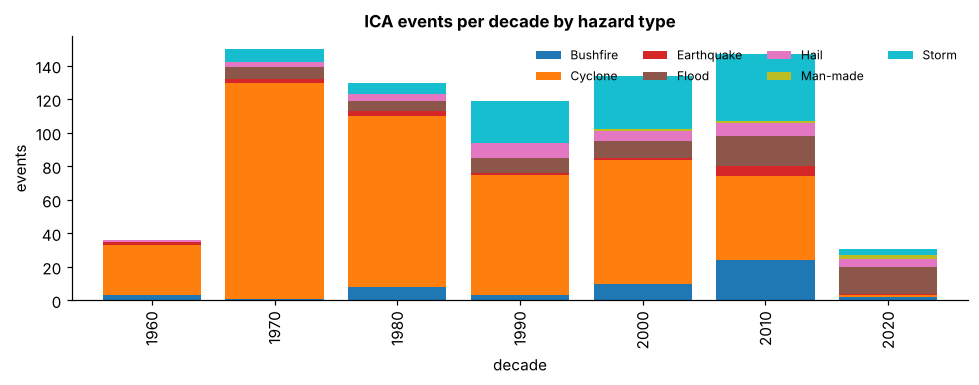

Events from 2011 onward: 164 of 747


,CAT Name,Event Name,Event Start,Type,State
2,SE262,Middle East Conflict,28-Feb-26,Man-made,Outside Australia
4,SE256,Bondi Event,14-Dec-25,Man-made,NSW
110,Undeclared,Urban Building Explosion,4-Sep-14,Man-made,
195,CAT085,Varanus Island Gas Disruption (CAT085),3-Jun-08,Man-made,


In [10]:
ica["_decade"] = (ica_start.dt.year // 10 * 10).astype("Int64")
ica["_year"] = ica_start.dt.year
mix = pd.crosstab(ica["_decade"], ica["Type"].str.strip())
display(mix)
ax = mix.plot(kind="bar", stacked=True, figsize=(9, 3.6), colormap="tab10", width=0.8)
ax.set(title="ICA events per decade by hazard type", xlabel="decade", ylabel="events")
ax.legend(ncol=4, fontsize=8, frameon=False)
savefig("ica_events_by_decade_type")
in_scope = ica_start.dt.year >= SCOPE_START_YEAR
print(f"Events from {SCOPE_START_YEAR} onward: {in_scope.sum()} of {len(ica)}")
nonnat = ica["Type"].str.strip().eq("Man-made")
display(ica.loc[nonnat, ["CAT Name", "Event Name", "Event Start", "Type", "State"]])
log_issue("DQ7", "ICA", "Type / State", "Validity (scope)", "Non-natural or overseas events", (nonnat | ica["State"].str.contains("Outside", na=False)).sum(),
          len(ica), "COVID-19; Middle East Conflict", "Send to etl_rejects with reason; never delete")

### 2.5 State: the integration problem
Every state value is put into one of six classes. Only one class can be used without a rule.

In [11]:
STATE_CODES = {"NSW", "VIC", "QLD", "SA", "WA", "TAS", "NT", "ACT"}
SUBSTATE = {"FNQ": "QLD", "SEQ": "QLD", "SWQ": "QLD", "NQ": "QLD", "CQ": "QLD"}

def classify_state(v):
    v = str(v).strip()
    if v == "": return "1 blank"
    if "outside" in v.lower(): return "6 outside Australia"
    if re.search(r",|\band\b|&|/", v): return "4 list of states/regions"
    if v.upper() in STATE_CODES: return "2 state code" if v == v.upper() else "3 state code, wrong case"
    if v.upper() in SUBSTATE: return "5 sub-state region code"
    return "7 other"

ica["_state_class"] = ica["State"].map(classify_state)
era = np.where(in_scope, f"{SCOPE_START_YEAR}+", f"before {SCOPE_START_YEAR}")
sc = pd.crosstab(ica["_state_class"], era, margins=True, margins_name="total")
save(sc.reset_index(), "ica_state_classes")
display(sc)
display(ica.loc[in_scope, "State"].replace("", "<blank>").value_counts().to_frame("events since 2011"))

col_0,2011+,before 2011,total
_state_class,,,
1 blank,109,405,514
2 state code,14,0,14
"3 state code, wrong case",1,0,1
4 list of states/regions,6,0,6
5 sub-state region code,33,178,211
6 outside Australia,1,0,1
total,164,583,747


,events since 2011
State,
<blank>,109
FNQ,18
SEQ,14
NSW,5
QLD,3
VIC,2
NSW and SEQ,2
WA,2
NT,1


**Can blank states be recovered?** Search the event name, town and description for a state name or a major city.

In [12]:
KEYWORDS = [("queensland", "QLD"), ("qld", "QLD"), ("far north", "QLD"), ("brisbane", "QLD"), ("townsville", "QLD"), ("cairns", "QLD"),
            ("new south wales", "NSW"), ("nsw", "NSW"), ("sydney", "NSW"), ("newcastle", "NSW"), ("victoria", "VIC"), ("melbourne", "VIC"),
            ("tasmania", "TAS"), ("hobart", "TAS"), ("western australia", "WA"), ("perth", "WA"), ("south australia", "SA"),
            ("adelaide", "SA"), ("northern territory", "NT"), ("darwin", "NT"), ("canberra", "ACT")]

def infer_states(text):
    t = " " + str(text).lower() + " "
    found = [code for kw, code in KEYWORDS if re.search(rf"\b{re.escape(kw)}\b", t)]
    return sorted(set(found))

blank_state = ica["State"].str.strip().eq("")
cand = (ica["Event Name"] + " " + ica["Town"] + " " + ica["Description"])[blank_state].map(infer_states)
rec = cand.map(len).map(lambda n: "no keyword found" if n == 0 else ("exactly one state" if n == 1 else "several states"))
recov = pd.crosstab(rec, np.asarray(era)[blank_state.values], margins=True, margins_name="total")
save(recov.reset_index(), "ica_blank_state_recovery")
display(recov)
display(pd.DataFrame({"Event Name": ica.loc[blank_state, "Event Name"], "inferred": cand}).head(10))

blank_scope = (blank_state & in_scope).sum()
one_scope = ((cand.map(len) == 1) & in_scope[blank_state]).sum()
finding(f"Since {SCOPE_START_YEAR}, {blank_scope} of {in_scope.sum()} events have no state, and the filled ones mix codes, "
        f"sub-state regions (FNQ, SEQ, SWQ), lists and mixed case. A keyword search recovers exactly one state for {one_scope} of the {blank_scope} blanks. "
        "The rest stay as Unknown (key −1) rather than being dropped.")
log_issue("DQ2", "ICA", "State", "Completeness / Consistency", "State blank, sub-state region, list or mixed case",
          (ica.loc[in_scope, "_state_class"] != "2 state code").sum(), in_scope.sum(), "FNQ; 'NSW and SEQ'; Vic; blank",
          "xw_state for codes/regions; first state + multi_state_flag for lists; keyword inference for blanks; else Unknown")

col_0,2011+,before 2011,total
row_0,,,
exactly one state,61,135,196
no keyword found,38,260,298
several states,10,10,20
total,109,405,514


,Event Name,inferred
10,Severe Weather NSW & QLD,"[NSW, QLD]"
11,Valentine's Day storms Victoria,[VIC]
12,Christmas Storms,"[NSW, QLD, VIC]"
13,TC Jasper and Far North Qld Flooding,[QLD]
28,COVID-19,[]
33,Northern NSW Rappville Bushfire (Amalgamated into CAT195),[NSW]
36,Kimberley Coast Earthquake,[WA]
37,Severe Weather NSW & VIC,"[NSW, VIC]"
38,NT Earthquake Event,"[NSW, NT]"
39,Bulloo Downs Earthquake,[QLD]


> **Finding:** Since 2011, 109 of 164 events have no state, and the filled ones mix codes, sub-state regions (FNQ, SEQ, SWQ), lists and mixed case. A keyword search recovers exactly one state for 61 of the 109 blanks. The rest stay as Unknown (key −1) rather than being dropped.

**Is the reported state right?** Compare the state column with the states named in the event name. A conflict means the state column is incomplete or wrong.

In [13]:
def reported_states(v):
    """All state codes named in the State column, after splitting lists and mapping regions (FNQ -> QLD)."""
    codes = {**{c: c for c in STATE_CODES}, **SUBSTATE}
    parts = re.split(r",|\band\b|&|/|;", v) if v.strip() else []
    return sorted({codes[p.strip().upper()] for p in parts if p.strip().upper() in codes})

rep_state = ica["State"].map(reported_states)
name_states = ica["Event Name"].map(infer_states)
conflict = (rep_state.map(len) > 0) & (name_states.map(len) > 0) & ~pd.Series([set(n) <= set(r) for n, r in zip(name_states, rep_state)], index=ica.index)
conf_tab = pd.DataFrame({"Event Name": ica["Event Name"], "State column": ica["State"], "states in name": name_states})[conflict]
display(conf_tab)
finding(f"{conflict.sum()} events name states that the `State` column leaves out, e.g. *{conf_tab.iloc[0, 0]}* is recorded as `{conf_tab.iloc[0, 1]}`. "
        "For multi-state events the state column is often only one of the affected states, so per-state loss is approximate.")
log_issue("DQ16", "ICA", "State vs Event Name", "Accuracy", "State column contradicts states named in the event", conflict.sum(),
          (rep_state.map(len) > 0).sum(), f"{conf_tab.iloc[0, 0]} → {conf_tab.iloc[0, 1]}",
          "Keep primary state; set multi_state_flag when the name lists more states; note as limitation")

,Event Name,State column,states in name
32,"2019/20 Bushfires (NSW,QLD,SA,VIC)",SEQ,"[NSW, QLD]"
34,NSW/QLD September 2019 Bushfires,SEQ,"[NSW, QLD]"
35,"Severe weather in SA, VIC, NSW, QLD, ACT",SEQ,"[NSW, QLD]"
425,Northern NSw and SW QLD Flooding,SWQ,"[NSW, QLD]"


> **Finding:** 4 events name states that the `State` column leaves out, e.g. *2019/20 Bushfires (NSW,QLD,SA,VIC)* is recorded as `SEQ`. For multi-state events the state column is often only one of the affected states, so per-state loss is approximate.

### 2.6 Insured loss
Losses are stored as text with `$` and commas. Check how much parses, how complete it is, how normalised compares with original, and how concentrated the loss is.

In [14]:
orig = to_num(ica["ORIGINAL LOSS VALUE"])
norm = to_num(ica["NORMALISED LOSS VALUE (2022)"])
loss_q = pd.DataFrame({
    "column": ["ORIGINAL LOSS VALUE", "NORMALISED LOSS VALUE (2022)"],
    "filled": [ica["ORIGINAL LOSS VALUE"].str.strip().ne("").sum(), ica["NORMALISED LOSS VALUE (2022)"].str.strip().ne("").sum()],
    "parsed_as_number": [orig.notna().sum(), norm.notna().sum()],
    "zero": [(orig == 0).sum(), (norm == 0).sum()],
    "negative": [(orig < 0).sum(), (norm < 0).sum()],
    "min_$": [orig.min(), norm.min()], "median_$": [orig.median(), norm.median()], "max_$": [orig.max(), norm.max()]})
display(loss_q.style.format({"min_$": "{:,.0f}", "median_$": "{:,.0f}", "max_$": "{:,.0f}"}))
unparsed = ica.loc[ica["ORIGINAL LOSS VALUE"].str.strip().ne("") & orig.isna(), "ORIGINAL LOSS VALUE"]
print("Filled but unparseable loss values:", unparsed.unique()[:10])

comp = pd.DataFrame({"decade": ica["_decade"], "loss filled %": orig.notna(), "claims filled %": to_num(ica["TOTAL CLAIMS RECEIVED"]).notna()})
comp = (comp.groupby("decade").mean() * 100).round(0)
comp["events"] = ica.groupby("_decade").size()
display(comp)

,column,filled,parsed_as_number,zero,negative,min_$,median_$,max_$
0,ORIGINAL LOSS VALUE,349,344,0,0,"100,000","19,250,000","6,375,616,815"
1,NORMALISED LOSS VALUE (2022),345,345,0,0,"100,000","128,500,000","8,845,700,000"


Filled but unparseable loss values: <StringArray>
[' $-   ']
Length: 1, dtype: str


,loss filled %,claims filled %,events
decade,,,
1960,28.0,0.0,36
1970,27.0,0.0,150
1980,24.0,0.0,130
1990,47.0,0.0,119
2000,51.0,0.0,134
2010,73.0,10.0,147
2020,97.0,97.0,31


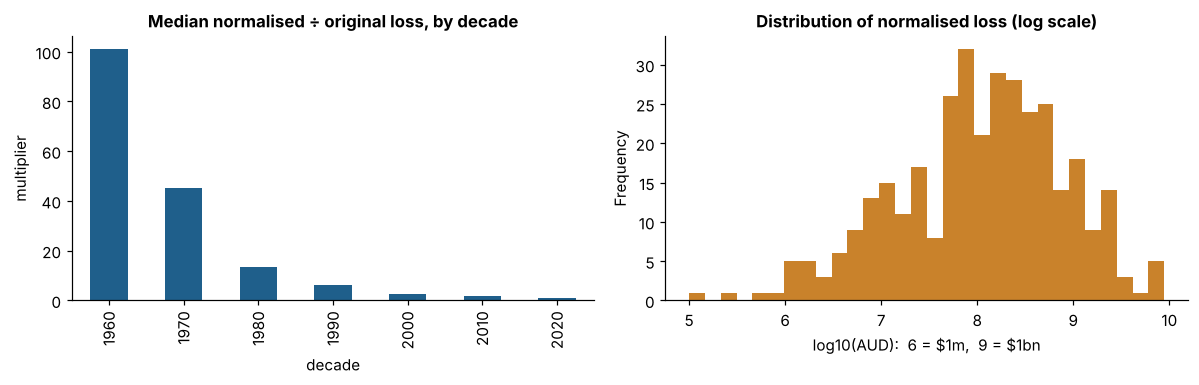

Rows where normalised < original: 0   (normalisation should never shrink a loss)


In [15]:
ratio = (norm / orig).replace([np.inf, -np.inf], np.nan)
r = pd.DataFrame({"decade": ica["_decade"], "normalised ÷ original": ratio}).groupby("decade")["normalised ÷ original"].median().round(1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
r.plot(kind="bar", ax=axes[0], color="#1f5f8b")
axes[0].set(title="Median normalised ÷ original loss, by decade", ylabel="multiplier", xlabel="decade")
np.log10(norm[norm > 0]).plot(kind="hist", bins=30, ax=axes[1], color="#c9822b")
axes[1].set(title="Distribution of normalised loss (log scale)", xlabel=r"log10(AUD):  6 = \$1m,  9 = \$1bn")
savefig("ica_loss_normalisation_and_distribution")
print(f"Rows where normalised < original: {(norm < orig).sum()}   (normalisation should never shrink a loss)")

,event,start,type,state,normalised_loss_$m
19,SE Queensland and NSW Floods,2022-02-21,Flood,NSW and SEQ,6375.6
5,QLD & NSW Severe Storms and Hail,2025-11-20,Storm,"QLD, NSW",2492.3
161,Brisbane Flooding,2011-01-11,Flood,SEQ,2450.4
109,Brisbane Hailstorm,2014-11-27,Hail,SEQ,2430.5
32,"2019/20 Bushfires (NSW,QLD,SA,VIC)",2019-11-08,Bushfire,SEQ,2405.4
64,Cyclone Debbie,2017-03-28,Cyclone,FNQ,2348.3
157,Cylone Yasi,2011-01-26,Cyclone,FNQ,2100.7
30,January Hailstorms,2020-01-18,Hail,SEQ,2025.3
47,NSW Hailstorm,2018-12-20,Hail,,1743.9
99,East Coast Low,2015-04-22,Storm,,1662.5


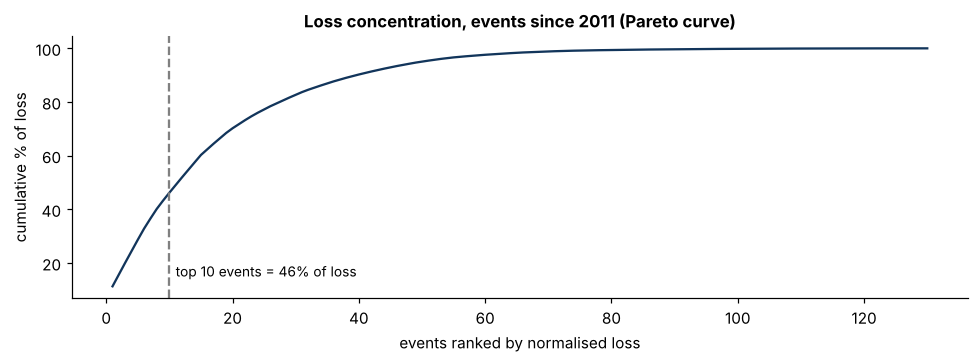

> **Finding:** Of 130 in-scope events with a loss value, the 10 largest carry **46%** of total normalised loss. Loss is missing for 34 in-scope events. That concentration is the core of BQ1 and the reinsurance argument.

In [16]:
scope_loss = pd.DataFrame({"event": ica["Event Name"], "start": ica_start.dt.date, "type": ica["Type"],
                           "state": ica["State"], "normalised_loss_$m": (norm / 1e6).round(1)})[in_scope & norm.notna()]
top = scope_loss.sort_values("normalised_loss_$m", ascending=False)
display(top.head(10))
s = top["normalised_loss_$m"].values
share_top10 = s[:10].sum() / s.sum()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(np.arange(1, len(s) + 1), np.cumsum(s) / s.sum() * 100, color="#12355b")
ax.axvline(10, ls="--", color="grey"); ax.text(11, 15, f"top 10 events = {share_top10:.0%} of loss", fontsize=9)
ax.set(title=f"Loss concentration, events since {SCOPE_START_YEAR} (Pareto curve)", xlabel="events ranked by normalised loss", ylabel="cumulative % of loss")
savefig("ica_loss_concentration")
finding(f"Of {len(s)} in-scope events with a loss value, the 10 largest carry **{share_top10:.0%}** of total normalised loss. "
        f"Loss is missing for {(in_scope & norm.isna()).sum()} in-scope events. That concentration is the core of BQ1 and the reinsurance argument.")
log_issue("DQ3", "ICA", "loss and claim columns", "Validity (type)", "Numbers stored as text with $, commas and '-'",
          ica["ORIGINAL LOSS VALUE"].str.contains(r"[\$,]").sum(), len(ica), ica["ORIGINAL LOSS VALUE"].iloc[0],
          "Strip $ , spaces; '-' and '$-' (accounting nil) = 0; blank = NULL")
log_issue("DQ3b", "ICA", "ORIGINAL / NORMALISED LOSS", "Completeness", "Loss value missing for in-scope events",
          (in_scope & norm.isna()).sum(), in_scope.sum(), "blank", "Keep event; loss NULL; exclude from averages, report coverage")

### 2.7 Claims columns
Are they counts or dollars, how complete are they, and do the nine claim types add up to the total?

In [17]:
claim_cols = [c for c in ica.columns if "laims" in c or c == "Commercial motor"]
claim_cols = [c for c in claim_cols if c != "TOTAL CLAIMS RECEIVED"]
total = to_num(ica["TOTAL CLAIMS RECEIVED"])
parts = pd.DataFrame({c: to_num(ica[c], dash_as_zero=True) for c in claim_cols})
cl = pd.DataFrame({"column": ["TOTAL CLAIMS RECEIVED"] + claim_cols,
                   "filled (all years)": [total.notna().sum()] + [parts[c].notna().sum() for c in claim_cols],
                   "filled since 2011": [total[in_scope].notna().sum()] + [parts.loc[in_scope, c].notna().sum() for c in claim_cols],
                   "'-' placeholders": [0] + [ica[c].str.strip().eq("-").sum() for c in claim_cols],
                   "max": [total.max()] + [parts[c].max() for c in claim_cols]})
display(cl)

have = total.notna()
diff = (parts.fillna(0).sum(axis=1) - total)[have]
recon = pd.DataFrame({"event": ica.loc[have, "Event Name"], "TOTAL": total[have], "sum of 9 parts": parts.fillna(0).sum(axis=1)[have], "difference": diff})
bad = recon[recon["difference"] != 0]
display(bad)
finding(f"Claims are **counts** (no `$`, whole numbers). Totals exist for only {have.sum()} events ({total[in_scope].notna().sum()} since {SCOPE_START_YEAR}), "
        f"so average cost per claim covers a minority of events. For {len(bad)} of those {have.sum()} the nine claim types do not add up to the total.")
log_issue("DQ8", "ICA", "claim-type columns", "Consistency", "Claim types don't sum to TOTAL CLAIMS RECEIVED", len(bad), have.sum(),
          f"{bad.iloc[0, 0]}: total {bad.iloc[0, 1]:.0f} vs parts {bad.iloc[0, 2]:.0f}" if len(bad) else "",
          "Keep ICA total as source of truth; flag mismatch; report breakdown as approximate")
log_issue("DQ9", "ICA", "TOTAL CLAIMS RECEIVED", "Completeness", "Claim count missing", (~have & in_scope).sum(), in_scope.sum(),
          "blank", "NULL, not 0; report KPI coverage beside cost-per-claim")

,column,filled (all years),filled since 2011,'-' placeholders,max
0,TOTAL CLAIMS RECEIVED,44,44,0,245985.0
1,Domestic Building Claims,46,43,2,134048.0
2,Domestic Content Claims,43,42,1,60973.0
3,Domestic Motor Claims,44,43,1,90897.0
4,Domestic Other Claims,40,40,2,1665.0
5,Commercial Property Claims,40,40,1,17333.0
6,Commercial motor,39,39,0,9375.0
7,Commercial BI Claims,39,39,1,1694.0
8,Commercial Other Claims,39,39,1,2105.0
9,Commercial Crop Claims,34,34,17,984.0


,event,TOTAL,sum of 9 parts,difference
2,Middle East Conflict,2126.0,2121.0,-5.0
26,Halloween Hail,44703.0,44704.0,1.0
29,South East Coast Storms & Flooding,102286.0,102376.0,90.0
32,"2019/20 Bushfires (NSW,QLD,SA,VIC)",38936.0,38908.0,-28.0
48,North Queensland Floods,525.0,0.0,-525.0
66,Sydney Hailstorms,50000.0,0.0,-50000.0
77,Western NSW Flooding,1200.0,0.0,-1200.0
78,East Coast Low,46363.0,0.0,-46363.0
90,Yarloop Bushfires,1358.0,0.0,-1358.0


> **Finding:** Claims are **counts** (no `$`, whole numbers). Totals exist for only 44 events (44 since 2011), so average cost per claim covers a minority of events. For 9 of those 44 the nine claim types do not add up to the total.

### 2.8 Completeness map
Fill rate of each important column by decade. Dark = complete.

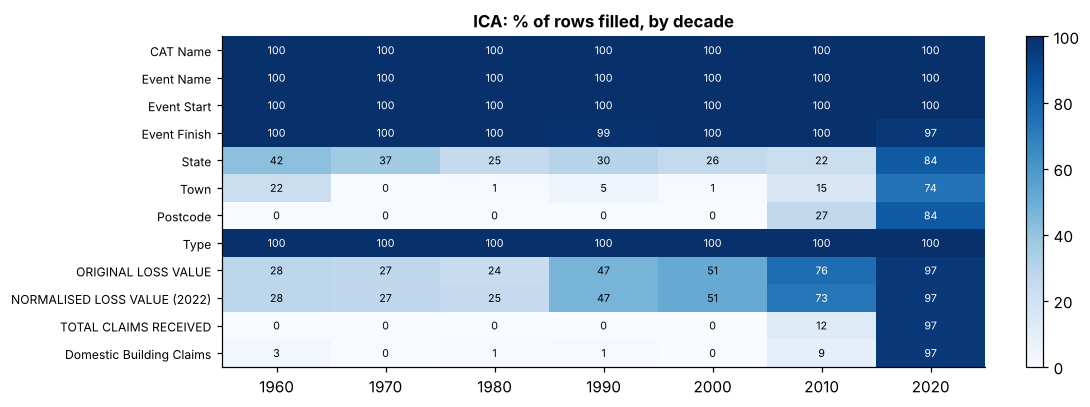

In [18]:
key_cols = ["CAT Name", "Event Name", "Event Start", "Event Finish", "State", "Town", "Postcode", "Type",
            "ORIGINAL LOSS VALUE", "NORMALISED LOSS VALUE (2022)", "TOTAL CLAIMS RECEIVED", "Domestic Building Claims"]
fill = ica[key_cols].apply(lambda c: c.str.strip().ne("")).groupby(ica["_decade"]).mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(fill.T.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(fill.index)), [str(d) for d in fill.index]); ax.set_yticks(range(len(key_cols)), key_cols, fontsize=8)
for i in range(len(key_cols)):
    for j in range(len(fill.index)):
        v = fill.T.values[i, j]; ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else "black")
ax.set_title("ICA: % of rows filled, by decade"); plt.colorbar(im, ax=ax, fraction=0.025)
savefig("ica_completeness_by_decade")

## 3. Disaster events (data.gov.au, government impact data)

In [19]:
de_prof = profile(de, "disaster_events")
display(de_prof)

,column,filled_%,blank,placeholder,distinct,unique?,numeric_%,formats,top_format,top_values
0,id,100.0,0,0,673,yes,100.0,4,999,1 (1); 2 (1); 3 (1)
1,resourceType,100.0,0,0,1,,0.0,1,Aaaaaaaa Aaaaa,Disaster Event (673)
2,title,100.0,0,0,670,,0.0,405,Aaaaaaaaa - Aaaaaaa,Hail - Western Sydney (2); Shipwreck - Sally (2); Shipwreck - Antares (2)
3,description,100.0,0,0,673,yes,0.0,575,Aa aaa aaaaaa aa 9999 - 9999 a…,"An extreme heatwave occur (1); On 13 June 1989, exceptio (1); On 24 July 197..."
4,startDate,100.0,0,0,655,,0.0,5,9/99/9999 9:99,01/01/1753 00:00:00 (3); 1/01/1939 0:00 (2); 1/13/1939 0:00 (2)
5,endDate,100.0,0,0,660,,0.0,5,9/99/9999 9:99,01/01/1753 00:00:00 (3); 6/30/2005 0:00 (3); 5/09/2006 0:00 (2)
6,lat,100.0,0,0,638,,100.0,10,-99.99999999,-19.25200272 (4); -33.87269592 (4); -27.47092438 (3)
7,lon,100.0,0,0,627,,100.0,10,999.9999999,146.8206024 (4); 151.2069855 (4); 153.0235443 (4)
8,documentType,0.0,673,0,0,,NaN,0,,
9,author,0.1,672,0,1,yes,0.0,1,Aaaaa Aaaaa,Karyn Stamp (1)


### 3.1 Two date formats in one column

In [20]:
display(de["startDate"].map(signature).value_counts().to_frame("rows"))
de_start, de_fmt = try_dates(de["startDate"].str.strip(), ["%m/%d/%Y %H:%M", "%d/%m/%Y %H:%M:%S"])
de_end, _ = try_dates(de["endDate"].str.strip(), ["%m/%d/%Y %H:%M", "%d/%m/%Y %H:%M:%S"])
fmt_tab = de_fmt.fillna("unparsed").value_counts().to_frame("rows")
display(fmt_tab)
single = pd.to_datetime(de["startDate"], format="%m/%d/%Y %H:%M", errors="coerce").isna().sum()
# ambiguity: values in the month-first format where the day is <= 12 could also be read day-first
mf = de_fmt.eq("%m/%d/%Y %H:%M")
ambig = (mf & (de_start.dt.day <= 12) & (de_start.dt.day != de_start.dt.month)).sum()
finding(f"`startDate` mixes month-first (`6/13/1989 0:00`) and day-first (`24/10/1829 00:00:00`) formats. "
        f"One format alone fails on {single} rows; trying both parses {de_start.notna().sum()} of {len(de)}. "
        f"{ambig} month-first dates have a day ≤ 12, so they would also parse wrongly as day-first. The format must be chosen by pattern, not guessed.")
log_issue("DQ5", "Disaster events", "startDate / endDate", "Consistency (format)", "Two date formats in one column", single, len(de),
          "6/13/1989 0:00 vs 24/10/1829 00:00:00", "Pick format by signature (time with seconds = day-first); record format used")

,rows
startDate,
9/99/9999 9:99,363
99/99/9999 9:99,145
99/99/9999 99:99:99,140
9/99/9999 99:99,23
99/99/9999 99:99,2


,rows
%m/%d/%Y %H:%M,533
%d/%m/%Y %H:%M:%S,140


> **Finding:** `startDate` mixes month-first (`6/13/1989 0:00`) and day-first (`24/10/1829 00:00:00`) formats. One format alone fails on 140 rows; trying both parses 673 of 673. 207 month-first dates have a day ≤ 12, so they would also parse wrongly as day-first. The format must be chosen by pattern, not guessed.

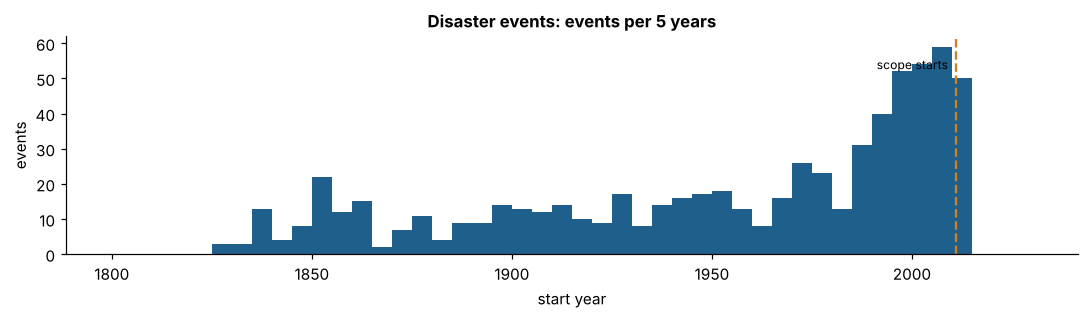

Range: 1753-01-01 to 2014-03-22  |  events since 2011: 44


,id,title,startDate,endDate
205,209,Shipwreck - Vergulde Draeck,01/01/1753 00:00:00,01/01/1753 00:00:00
272,276,Shipwreck - Zeewijk,01/01/1753 00:00:00,01/01/1753 00:00:00
462,467,Shipwreck - Trial (Tryal),01/01/1753 00:00:00,01/01/1753 00:00:00


> **Finding:** 3 events are dated exactly **1 January 1753**, the minimum date of SQL Server's DATETIME type. These are shipwrecks from the 1600s–1700s (the Zeewijk sank in 1727), so the real date was clamped to a placeholder by an earlier system. They are out of scope, but this is a textbook accuracy problem.

In [21]:
de_year = de_start.dt.year
fig, ax = plt.subplots(figsize=(10, 3))
de_year.dropna().astype(int).plot(kind="hist", bins=np.arange(1800, 2031, 5), ax=ax, color="#1f5f8b")
ax.axvline(SCOPE_START_YEAR, color="#c9822b", ls="--"); ax.text(SCOPE_START_YEAR - 2, ax.get_ylim()[1] * 0.85, "scope starts", ha="right", fontsize=8)
ax.set(title="Disaster events: events per 5 years", xlabel="start year", ylabel="events")
savefig("de_events_over_time")
print(f"Range: {de_start.min().date()} to {de_start.max().date()}  |  events since {SCOPE_START_YEAR}: {(de_year >= SCOPE_START_YEAR).sum()}")

# 1 Jan 1753 is the earliest date SQL Server's DATETIME type can hold: a classic placeholder for "real date didn't fit"
sentinel = de_start.eq(pd.Timestamp("1753-01-01"))
display(de.loc[sentinel, ["id", "title", "startDate", "endDate"]])
if sentinel.any():
    finding(f"{sentinel.sum()} events are dated exactly **1 January 1753**, the minimum date of SQL Server's DATETIME type. "
            "These are shipwrecks from the 1600s–1700s (the Zeewijk sank in 1727), so the real date was clamped to a placeholder by an earlier system. "
            "They are out of scope, but this is a textbook accuracy problem.")
    log_issue("DQ18", "Disaster events", "startDate", "Accuracy", "Placeholder date 1753-01-01 (SQL Server minimum)", sentinel.sum(), len(de),
              de.loc[sentinel, "title"].iloc[0], "Treat 1753-01-01 as unknown date (NULL); event is out of scope anyway")
log_issue("DQ10", "Disaster events", "startDate", "Timeliness", f"File ends {de_start.max():%b %Y}; little overlap with scope",
          (de_year < SCOPE_START_YEAR).sum(), len(de), f"last event {de_start.max().date()}",
          "Use only to enrich matched events; document as limitation")

### 3.2 What kinds of events, and where

In [22]:
de["_prefix"] = de["title"].str.split(" - ").str[0].str.strip()
# some cyclone titles put the storm name in the category: "Cyclone Tracy - Darwin" or "Cyclone Yasi, Queensland, 2011"
de["_category"] = np.where(de["_prefix"].str.startswith("Cyclone"), "Cyclone", de["_prefix"])
odd = de["_prefix"].ne(de["_category"])
print(f"Titles whose category is not in the standard 'Category - place' form: {odd.sum()}")
display(de.loc[odd, "title"].head(5).to_frame())
log_issue("DQ17", "Disaster events", "title", "Consistency (format)", "Hazard category embedded inconsistently in title", odd.sum(), len(de),
          de.loc[odd, "title"].iloc[0], "Category = text before ' - '; any prefix starting 'Cyclone' = Cyclone")
cats = de["_category"].value_counts()
NATURAL = {"Flood", "Bushfire", "Severe Storm", "Hail", "Cyclone", "Earthquake", "Landslide", "Tsunami", "Tornado"}
catdf = cats.to_frame("events"); catdf["natural hazard?"] = ["yes" if c in NATURAL else "" for c in catdf.index]
display(catdf)
nat_share = de["_category"].isin(NATURAL).mean()
finding(f"Only {nat_share:.0%} of disaster events are natural hazards. The file also holds shipwrecks, transport, industrial and epidemic events, which are out of scope.")

reg_parts = de["regions"].str.split(";")
reg_class = np.select([de["regions"].str.strip().eq(""), de["regions"].str.contains("Outside"), reg_parts.str.len() > 1],
                      ["blank", "outside Australia", "several states (';' separated)"], "one state")
display(pd.Series(reg_class).value_counts().to_frame("events"))
finding(f"`regions` is a **semicolon-separated list**: {(reg_parts.str.len() > 1).sum()} events name several states, e.g. `{de.loc[reg_parts.str.len() > 1, 'regions'].iloc[0]}`. It has to be split before it can be matched to a single state.")
lat, lon = pd.to_numeric(de["lat"], errors="coerce"), pd.to_numeric(de["lon"], errors="coerce")
outside_box = ~(lat.between(-44.5, -9) & lon.between(112, 154.5))
print(f"Coordinates outside Australia's bounding box: {outside_box.sum()}  (regions says 'Outside Australia': {de['regions'].eq('Outside Australia').sum()})")

Titles whose category is not in the standard 'Category - place' form: 28


,title
11,Cyclone George
28,Cyclone Justin
40,Cyclone Winifred
41,Cyclone Mahina
45,Cyclone Glenda


,events,natural hazard?
_category,,
Shipwreck,169,
Transport,107,
Flood,78,yes
Bushfire,57,yes
Severe Storm,47,yes
Industrial,38,
Cyclone,38,yes
Environmental,31,
Urban Fire,23,


> **Finding:** Only 38% of disaster events are natural hazards. The file also holds shipwrecks, transport, industrial and epidemic events, which are out of scope.

,events
one state,595
several states (';' separated),48
outside Australia,29
blank,1


> **Finding:** `regions` is a **semicolon-separated list**: 49 events name several states, e.g. `Victoria;New South Wales;South Australia`. It has to be split before it can be matched to a single state.

Coordinates outside Australia's bounding box: 36  (regions says 'Outside Australia': 28)


### 3.3 Impact columns are mostly empty

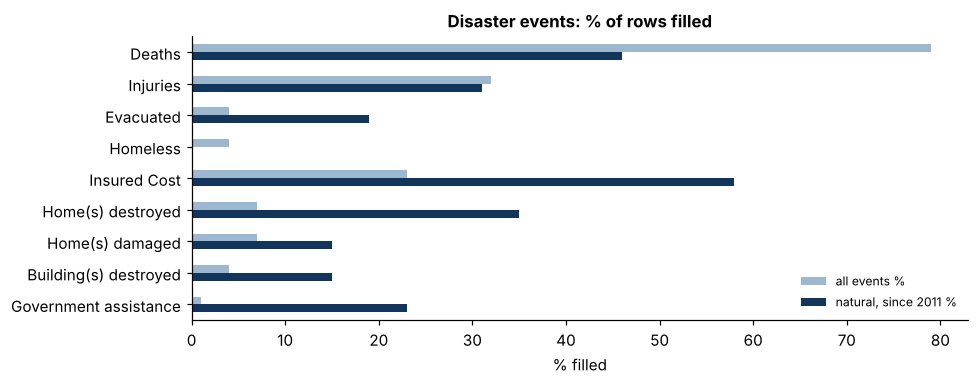

,all events %,"natural, since 2011 %"
Deaths,79.0,46.0
Injuries,32.0,31.0
Evacuated,4.0,19.0
Homeless,4.0,0.0
Insured Cost,23.0,58.0
Home(s) destroyed,7.0,35.0
Home(s) damaged,7.0,15.0
Building(s) destroyed,4.0,15.0
Government assistance,1.0,23.0


Descriptions containing HTML entities such as '&deg;': 193  e.g. &deg;


In [23]:
impact = ["Deaths", "Injuries", "Evacuated", "Homeless", "Insured Cost", "Home(s) destroyed", "Home(s) damaged",
          "Building(s) destroyed", "Government assistance"]
imp = pd.DataFrame({"all events %": [de[c].str.strip().ne("").mean() * 100 for c in impact],
                    "natural, since 2011 %": [de.loc[de["_category"].isin(NATURAL) & (de_year >= SCOPE_START_YEAR), c].str.strip().ne("").mean() * 100 for c in impact]},
                   index=impact).round(0)
ax = imp.plot(kind="barh", figsize=(9, 3.6), color=["#9db7cf", "#12355b"]); ax.invert_yaxis()
ax.set(title="Disaster events: % of rows filled", xlabel="% filled"); ax.legend(frameon=False, fontsize=8)
savefig("de_impact_fill_rates")
display(imp)
ent = de["description"].str.contains(r"&[a-z]+;|&#\d+;", regex=True).sum()
print(f"Descriptions containing HTML entities such as '&deg;': {ent}  e.g. {re.search(r'&[a-z]+;', de.loc[de['description'].str.contains('&[a-z]+;'), 'description'].iloc[0]).group()}")
log_issue("DQ11", "Disaster events", "description", "Validity (format)", "HTML entities in text", ent, len(de), "&deg;", "html.unescape() in staging view")
log_issue("DQ12", "Disaster events", "Deaths … Insured Cost", "Completeness", "Impact measures mostly blank (Insured Cost)",
          de["Insured Cost"].str.strip().eq("").sum(), len(de), "blank", "Blank = NULL (unknown), never 0")

## 4. ABS Data by Region: population and income

### 4.1 What the rows actually are
The `Code` column mixes six geography levels, plus footer notes. Only the eight states and territories are needed.

In [24]:
def geo_level(code):
    code = str(code).strip()
    if re.fullmatch(r"AUS", code): return "0 Australia"
    if re.fullmatch(r"\d", code): return "1 State / territory"
    if re.fullmatch(r"\d[A-Z]{4}", code): return "2 Greater capital city (GCCSA)"
    if re.fullmatch(r"\d{3}", code): return "3 SA4"
    if re.fullmatch(r"\d{5}", code): return "4 SA3"
    if re.fullmatch(r"\d{9}", code): return "5 SA2"
    return "9 not data (notes, legend, copyright, blank)"

for name, df in [("population", pop), ("income", inc)]:
    df["_level"] = df["Code"].map(geo_level)
lv = pd.concat([pop["_level"].value_counts().rename("population rows"), inc["_level"].value_counts().rename("income rows")], axis=1).sort_index()
save(lv.reset_index(), "abs_geography_levels")
display(lv)
display(pop.loc[pop["_level"].str.startswith("9"), ["Code", "Label"]])
finding(f"Only {(pop['_level'] == '1 State / territory').sum()} of {len(pop):,} population rows are state-level. "
        f"{(pop['_level'].str.startswith('9')).sum()} rows at the bottom are notes, a legend for '-' and a copyright line, which must be rejected, not loaded as data. "
        "'Other Territories' (code 9) has no events and is excluded by the state crosswalk.")
log_issue("DQ13", "ABS", "Code", "Validity", "Footer notes/legend/copyright rows inside the data", (pop["_level"].str.startswith("9")).sum() + (inc["_level"].str.startswith("9")).sum(),
          len(pop) + len(inc), "© Commonwealth of Australia 2026", "Keep rows where Code is a 1-digit state code 1–8; reject the rest with reason")

,population rows,income rows
_level,,
0 Australia,9,11
1 State / territory,81,99
2 Greater capital city (GCCSA),144,176
3 SA4,801,979
4 SA3,3060,3740
5 SA2,22086,26994
"9 not data (notes, legend, copyright, blank)",7,7


,Code,Label
26181,,
26182,,
26183,"Note: Main Structure and Greater Capital City Statistical Areas, Australian ...",
26184,,
26185,-,"data not available, not available for publication, nil or rounded to zero, i..."
26186,,
26187,© Commonwealth of Australia 2026,


> **Finding:** Only 81 of 26,188 population rows are state-level. 7 rows at the bottom are notes, a legend for '-' and a copyright line, which must be rejected, not loaded as data. 'Other Territories' (code 9) has no events and is excluded by the state crosswalk.

### 4.2 Which years have values?
ABS uses `-` for "not available". At state level, count how many of the 8 states have a real value per year.

In [25]:
POP_COL = "Estimated resident population (no.)"
INC_COL = "Median total income (excl. Government pensions and allowances) ($)"
st_pop = pop[pop["Code"].str.fullmatch(r"[1-8]")]
st_inc = inc[inc["Code"].str.fullmatch(r"[1-8]")]
avail = pd.concat([
    st_pop.groupby("Year")[POP_COL].apply(lambda s: (~s.str.strip().isin(PLACEHOLDERS | {""})).sum()).rename("states with population"),
    st_inc.groupby("Year")[INC_COL].apply(lambda s: (~s.str.strip().isin(PLACEHOLDERS | {""})).sum()).rename("states with median income"),
], axis=1).fillna(0).astype(int)
save(avail.reset_index(), "abs_year_availability")
display(avail)

state_pop = st_pop.assign(v=to_num(st_pop[POP_COL])).pivot_table(index="Label", columns="Year", values="v")
state_inc = st_inc.assign(v=to_num(st_inc[INC_COL])).pivot_table(index="Label", columns="Year", values="v")
print("State population (persons):"); display(state_pop.style.format("{:,.0f}", na_rep="–"))
print("Median total income ($ per year):"); display(state_inc.style.format("{:,.0f}", na_rep="–"))

pop_years = avail.index[avail["states with population"] > 0].tolist()
inc_years = avail.index[avail["states with median income"] > 0].tolist()
gaps = sum(1 for y in range(SCOPE_START_YEAR, CURRENT_YEAR + 1) if str(y) not in pop_years) + \
       sum(1 for y in range(SCOPE_START_YEAR, CURRENT_YEAR + 1) if str(y) not in inc_years)
finding(f"Population is available only for {pop_years[0]}–{pop_years[-1]} and median income only for {inc_years[0]}–{inc_years[-1]}, "
        f"although the file lists more years. For the {SCOPE_START_YEAR}–{CURRENT_YEAR} scope, most state-years need a value borrowed from the nearest available year.")
log_issue("DQ6", "ABS", "population / median income", "Completeness", "Values missing ('-') for most scope years", gaps * 8,
          2 * 8 * (CURRENT_YEAR - SCOPE_START_YEAR + 1), "'-' in 2011, 2016, 2019 population",
          "Nearest available year (earlier wins ties); store year used + is_imputed flag")

legend = pop.loc[pop["Code"].str.strip().eq("-"), "Label"]
if len(legend):
    print("ABS legend for '-':", legend.iloc[0])
log_issue("SEM3", "ICA vs ABS", "'-' symbol", "Consistency (semantic)", "'-' means zero claims in ICA but 'not available' in ABS",
          ica[claim_cols].apply(lambda c: c.str.strip().eq("-")).sum().sum(), len(ica),
          "ABS: 'data not available … nil or rounded to zero'", "ICA claim '-' -> 0; ABS '-' -> NULL then nearest-year rule")

,states with population,states with median income
Year,,
2011,0,0
2016,0,0
2019,0,8
2020,8,8
2021,8,8
2022,8,8
2023,8,8
2024,8,0
2025,8,0


State population (persons):


Year,2020,2021,2022,2023,2024,2025
Label,,,,,,
Australian Capital Territory,"444,903","452,508","461,262","471,340","478,430","484,630"
New South Wales,"8,110,610","8,097,062","8,182,098","8,356,387","8,492,050","8,592,524"
Northern Territory,"247,428","248,151","253,100","257,508","260,884","264,556"
Queensland,"5,165,613","5,215,814","5,310,905","5,450,235","5,571,890","5,669,764"
South Australia,"1,790,355","1,802,601","1,824,969","1,857,646","1,882,164","1,902,665"
Tasmania,"557,578","567,239","572,300","573,731","574,765","576,261"
Victoria,"6,615,046","6,547,822","6,615,232","6,797,169","6,950,961","7,073,859"
Western Australia,"2,712,912","2,749,365","2,793,934","2,890,936","2,978,147","3,044,382"


Median total income ($ per year):


Year,2019,2020,2021,2022,2023
Label,,,,,
Australian Capital Territory,"64,941","66,705","69,743","72,115","75,643"
New South Wales,"49,522","50,567","53,905","55,105","58,909"
Northern Territory,"57,683","58,310","62,409","65,301","66,831"
Queensland,"47,905","48,920","51,557","54,076","56,708"
South Australia,"47,939","48,616","50,976","53,353","55,782"
Tasmania,"45,009","45,809","48,161","50,645","53,479"
Victoria,"48,801","49,848","52,218","54,708","57,907"
Western Australia,"51,886","52,907","56,415","59,426","62,207"


> **Finding:** Population is available only for 2020–2025 and median income only for 2019–2023, although the file lists more years. For the 2011–2026 scope, most state-years need a value borrowed from the nearest available year.

ABS legend for '-': data not available, not available for publication, nil or rounded to zero, including null cells


In [26]:
dup_headers = [c for c in inc.columns if re.search(r"\.\d+$", c)]
print("Duplicate header names in the income file (pandas added '.1'):")
for c in dup_headers: print("  ", c)
log_issue("DQ14", "ABS income", "income-band columns", "Validity (structure)", "Duplicate column names", len(dup_headers),
          inc.shape[1], dup_headers[0] if dup_headers else "", "Load only needed columns; rename with prefixes")

Duplicate header names in the income file (pandas added '.1'):
   $1-$499 per week (%).1
   $500-$999 per week (%).1
   $1000-$1999 per week (%).1
   $2000-$2999 per week (%).1
   $3000 or more per week (%).1
   Nil income (%).1


## 5. Cross-source integration
The sources share no key. These checks show whether they can be conformed on **state**, **hazard**, **time** and finally **event**.

### 5.1 State vocabularies

In [27]:
XW_STATE = {**{c: c for c in STATE_CODES}, **SUBSTATE, "NEW SOUTH WALES": "NSW", "VICTORIA": "VIC", "QUEENSLAND": "QLD",
            "SOUTH AUSTRALIA": "SA", "WESTERN AUSTRALIA": "WA", "TASMANIA": "TAS", "NORTHERN TERRITORY": "NT",
            "AUSTRALIAN CAPITAL TERRITORY": "ACT"}

def first_state(v):
    v = str(v).strip()
    if v == "": return None
    return re.split(r",|\band\b|&|/|;", v)[0].strip().upper()

rows = []
de_regions_exploded = de["regions"].str.split(";").explode().str.strip()
for src, series in [("ICA State", ica["State"]), ("Disaster events regions (split on ';')", de_regions_exploded), ("ABS Label (state rows)", st_pop["Label"])]:
    vals = series.str.strip()
    for v, n in vals.replace("", "<blank>").value_counts().items():
        p = first_state(v) if v != "<blank>" else None
        rows.append({"source": src, "value": v, "rows": n, "maps to": XW_STATE.get(p, "—") if p else "—"})
vocab = pd.DataFrame(rows)
save(vocab, "cross_state_vocabulary")
summary = vocab.assign(mapped=vocab["maps to"].ne("—")).groupby(["source", "mapped"])["rows"].sum().unstack(fill_value=0)
display(summary)
display(vocab[vocab["maps to"].eq("—")])

mapped,False,True
source,,
ABS Label (state rows),0,72
Disaster events regions (split on ';'),30,858
ICA State,515,232


,source,value,rows,maps to
0,ICA State,<blank>,514,—
10,ICA State,Outside Australia,1,—
25,Disaster events regions (split on ';'),Outside Australia,29,—
26,Disaster events regions (split on ';'),<blank>,1,—


### 5.2 Hazard vocabularies

In [28]:
XW_HAZ = {"Cyclone": "Cyclone", "Storm": "Storm", "Severe Storm": "Storm", "Tornado": "Storm", "Hail": "Hail", "Flood": "Flood",
          "Bushfire": "Bushfire", "Earthquake": "Earthquake"}
hz = pd.concat([ica["Type"].str.strip().value_counts().rename("ICA Type"),
                de["_category"].value_counts().rename("Disaster events title prefix")], axis=1).fillna(0).astype(int)
hz["hazard group"] = [XW_HAZ.get(i, "— out of scope") for i in hz.index]
display(hz.sort_values("hazard group"))
finding("ICA says `Storm`; disaster events says `Severe Storm` or `Tornado`. ICA has `Man-made`; disaster events has a dozen non-natural categories. An eight-row hazard crosswalk conforms both.")

,ICA Type,Disaster events title prefix,hazard group
Bushfire,51,57,Bushfire
Cyclone,458,38,Cyclone
Earthquake,16,9,Earthquake
Flood,66,78,Flood
Hail,36,21,Hail
Storm,116,0,Storm
Tornado,0,3,Storm
Severe Storm,0,47,Storm
Tsunami,0,2,— out of scope
Landslide,0,4,— out of scope


> **Finding:** ICA says `Storm`; disaster events says `Severe Storm` or `Tornado`. ICA has `Man-made`; disaster events has a dozen non-natural categories. An eight-row hazard crosswalk conforms both.

### 5.3 Time coverage

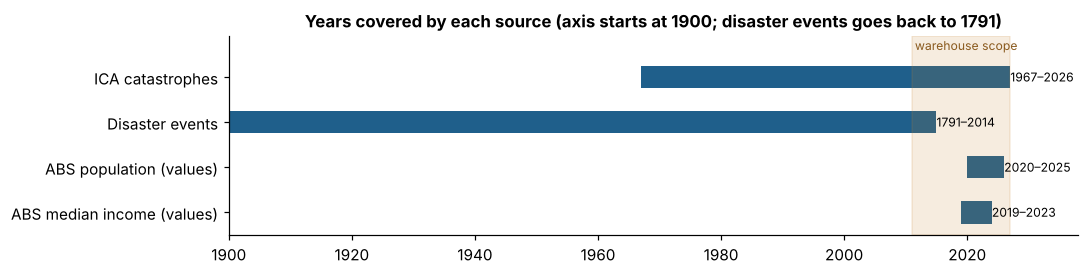

,source,from,to
0,ICA catastrophes,1967,2026
1,Disaster events,1791,2014
2,ABS population (values),2020,2025
3,ABS median income (values),2019,2023


In [29]:
spans = pd.DataFrame([
    ("ICA catastrophes", ica_start.min().year, ica_start.max().year),
    ("Disaster events", de_start[~sentinel].min().year, de_start.max().year),   # ignores the 1753 placeholder
    ("ABS population (values)", int(pop_years[0]), int(pop_years[-1])),
    ("ABS median income (values)", int(inc_years[0]), int(inc_years[-1])),
], columns=["source", "from", "to"])
fig, ax = plt.subplots(figsize=(10, 2.6))
for i, r_ in spans.iterrows():
    ax.barh(i, r_["to"] - r_["from"] + 1, left=r_["from"], color="#1f5f8b", height=0.5)
    ax.text(r_["to"] + 1, i, f"{r_['from']}–{r_['to']}", va="center", fontsize=8)
ax.axvspan(SCOPE_START_YEAR, CURRENT_YEAR + 1, color="#c9822b", alpha=0.15)
ax.text(SCOPE_START_YEAR + 0.5, -0.6, "warehouse scope", fontsize=8, color="#8a5a1e")
ax.set_yticks(range(len(spans)), spans["source"]); ax.set_ylim(len(spans) - 0.5, -0.9); ax.set_xlim(1900, CURRENT_YEAR + 12)
ax.set_title(f"Years covered by each source (axis starts at 1900; disaster events goes back to {de_start[~sentinel].min().year})")
savefig("cross_time_coverage")
display(spans)

### 5.4 Can ICA events be matched to disaster events?
Rule tested: same state, same hazard group, start dates within 7 days. Run over **all years** where both files overlap, then over the scope.

In [30]:
# ICA state: reported (first listed) state, else the single state inferred from the text in 2.5
reported = ica["State"].map(first_state).map(XW_STATE)
inferred_one = (ica["Event Name"] + " " + ica["Town"] + " " + ica["Description"]).map(infer_states).map(lambda l: l[0] if len(l) == 1 else None)
ica_m = pd.DataFrame({"ica_row": ica.index, "name": ica["Event Name"], "start": ica_start,
                      "state": reported.fillna(inferred_one), "hazard": ica["Type"].str.strip().map(XW_HAZ), "ica_loss": orig})
# disaster events: one row per (event, state) after splitting the ';' list
de_m = pd.DataFrame({"de_row": de.index, "title": de["title"], "de_start": de_start, "regions": de["regions"].str.split(";"),
                     "hazard": de["_category"].map(XW_HAZ), "de_insured_cost": to_num(de["Insured Cost"])}).explode("regions")
de_m["state"] = de_m["regions"].str.strip().str.upper().map(XW_STATE)
pairs = ica_m.dropna(subset=["state", "hazard", "start"]).merge(de_m.dropna(subset=["state", "hazard", "de_start"]), on=["state", "hazard"])
pairs["day_gap"] = (pairs["de_start"] - pairs["start"]).dt.days.abs()
pairs = pairs[pairs["day_gap"] <= 7].sort_values(["ica_row", "day_gap"]).drop_duplicates("ica_row")

overlap = ica_start.dt.year.between(de_start.min().year, de_start.max().year)
res = pd.DataFrame([
    {"ICA events": "overlap period, all", "count": overlap.sum(), "matched": pairs["ica_row"].isin(ica.index[overlap]).sum()},
    {"ICA events": "overlap period, state known", "count": (overlap & ica_m["state"].notna()).sum(),
     "matched": pairs["ica_row"].isin(ica.index[overlap & ica_m["state"].notna()]).sum()},
    {"ICA events": f"in scope ({SCOPE_START_YEAR}+)", "count": in_scope.sum(), "matched": pairs["ica_row"].isin(ica.index[in_scope]).sum()},
])
res["match rate %"] = (100 * res["matched"] / res["count"]).round(1)
save(res, "cross_match_feasibility")
display(res)
display(pairs[["name", "start", "title", "de_start", "state", "hazard", "day_gap"]].head(12).reset_index(drop=True))
reused = pairs["de_row"].duplicated().sum()
print(f"Disaster-events rows matched to more than one ICA event: {reused}  -> rule: keep the closest start date, tie-break on name similarity")
m_scope = res.iloc[2]
finding(f"Using state (reported or inferred), hazard and a ±7-day window, {res.iloc[0]['matched']} ICA events match a disaster event across the overlap period, "
        f"but only {m_scope['matched']} of {m_scope['count']} in-scope events do, because disaster events stops in 2014. "
        "Human-impact measures (deaths, evacuations) will be NULL for almost every in-scope fact row: a limitation, not an ETL failure.")

,ICA events,count,matched,match rate %
0,"overlap period, all",640,96,15.0
1,"overlap period, state known",348,96,27.6
2,in scope (2011+),164,10,6.1


,name,start,title,de_start,state,hazard,day_gap
0,Victorian Bushfires,2014-02-07,"Bushfire - Victoria, 2014",2014-02-09 11:23:00,VIC,Bushfire,2
1,Perth Hills Bushfire,2014-01-12,"Bushfire - Perth Hills, January 2014",2014-01-11 10:27:00,WA,Bushfire,1
2,Blue Mountains Bushfires,2013-10-17,Bushfire - New South Wales 2013,2013-10-13 00:00:00,NSW,Bushfire,4
3,Eastern Victorian Tornado Cluster,2013-03-21,Tornado - Murray River Townships,2013-03-21 11:31:00,VIC,Storm,0
4,NSW Flooding Ex Cyclone Oswald,2013-01-22,"Cyclone Oswald, Queensland & New South Wales, 2013",2013-01-21 09:49:00,NSW,Cyclone,1
5,QLD Flooding Ex Cyclone Oswald,2013-01-20,"Cyclone Oswald, Queensland & New South Wales, 2013",2013-01-21 09:49:00,QLD,Cyclone,1
6,Warrumbungle Bushfires,2013-01-07,"Bushfire - Coonabarabran, New South Wales 2013",2013-01-07 14:41:00,NSW,Bushfire,0
7,Bachus Marsh Tornado,2011-12-25,"Severe Storm - Melbourne, December 2011",2011-12-25 00:00:00,VIC,Storm,0
8,WA Bushfires,2011-02-05,"Bushfire - Perth Hills, Western Australia 2011",2011-02-05 00:00:00,WA,Bushfire,0
9,Rural Victoria Flooding,2011-01-12,Flood - Victoria Jan 2011,2011-01-12 00:00:00,VIC,Flood,0


Disaster-events rows matched to more than one ICA event: 7  -> rule: keep the closest start date, tie-break on name similarity


> **Finding:** Using state (reported or inferred), hazard and a ±7-day window, 96 ICA events match a disaster event across the overlap period, but only 10 of 164 in-scope events do, because disaster events stops in 2014. Human-impact measures (deaths, evacuations) will be NULL for almost every in-scope fact row: a limitation, not an ETL failure.

### 5.5 Do the two sources agree on insured cost?
For matched events where both files give an insured figure.

In [31]:
both = pairs.dropna(subset=["ica_loss", "de_insured_cost"])
both = both[both["ica_loss"] > 0].assign(ratio=lambda d: (d["de_insured_cost"] / d["ica_loss"]).round(2))
display(both[["name", "start", "ica_loss", "de_insured_cost", "ratio"]].sort_values("ratio")
        .style.format({"ica_loss": "{:,.0f}", "de_insured_cost": "{:,.0f}"}))
if len(both):
    exact = both["ratio"].between(0.95, 1.05).sum()
    wild = both[(both["ratio"] < 0.5) | (both["ratio"] > 2)]
    finding(f"Of {len(both)} matched events with an insured figure in both sources, **{exact} agree within ±5%**, most of them to the dollar. "
            "Disaster events evidently copied ICA's figure, so it is an older copy, not an independent measure: loading both would double count. "
            f"Small gaps (e.g. $415.9m vs $415.0m) look like later ICA revisions. The {len(wild)} large gaps (ratio below 0.5 or above 2) are more likely "
            "**wrong matches**, so spot-check them before trusting the match rule.")
    display(wild[["name", "start", "title", "de_start", "ica_loss", "de_insured_cost", "ratio"]].reset_index(drop=True))
    log_issue("SEM2", "ICA vs Disaster events", "ORIGINAL LOSS vs Insured Cost", "Consistency (semantic)",
              "Same insured loss stored twice; some copies differ", len(both) - exact, len(both),
              f"{both.iloc[0]['name']}: ratio {both.iloc[0]['ratio']}", "Load ICA only; disaster-events figure used just to validate matches")

,name,start,ica_loss,de_insured_cost,ratio
1496,Perth Hills Bushfire,2014-01-12 00:00:00,"87,812,300","15,000,000",0.170000
8264,Bushfire,1967-02-07 00:00:00,"40,000,000","14,000,000",0.350000
3061,Sydney Region Severe Storm,2002-02-16 00:00:00,"18,600,000","10,000,000",0.540000
4729,Sydney Region Storms,1991-01-21 00:00:00,"215,400,000","138,400,000",0.640000
3134,Northern Rivers Severe Storm,2002-01-16 00:00:00,"12,500,000","10,000,000",0.800000
1558,Blue Mountains Bushfires,2013-10-17 00:00:00,"193,450,500","183,400,000",0.950000
1872,Rural Victoria Flooding,2011-01-12 00:00:00,"128,495,000","126,495,000",0.980000
4366,Blue Mountains Severe Weather,1994-11-20 00:00:00,"29,200,000","29,000,000",0.990000
2250,Floods,2009-01-31 00:00:00,"19,000,000","19,000,000",1.000000
2271,Queensland Storms (CAT086),2008-11-16 00:00:00,"309,000,000","309,000,000",1.000000


> **Finding:** Of 81 matched events with an insured figure in both sources, **67 agree within ±5%**, most of them to the dollar. Disaster events evidently copied ICA's figure, so it is an older copy, not an independent measure: loading both would double count. Small gaps (e.g. $415.9m vs $415.0m) look like later ICA revisions. The 9 large gaps (ratio below 0.5 or above 2) are more likely **wrong matches**, so spot-check them before trusting the match rule.

,name,start,title,de_start,ica_loss,de_insured_cost,ratio
0,Perth Hills Bushfire,2014-01-12,"Bushfire - Perth Hills, January 2014",2014-01-11 10:27:00,87812300.0,1.500000e+07,0.17
1,NSW Flooding Ex Cyclone Oswald,2013-01-22,"Cyclone Oswald, Queensland & New South Wales, 2013",2013-01-21 09:49:00,125310500.0,1.098000e+09,8.76
2,Bachus Marsh Tornado,2011-12-25,"Severe Storm - Melbourne, December 2011",2011-12-25 00:00:00,1800000.0,7.286400e+08,404.80
3,Dubbo Severe Storm Event,2001-01-17,Severe Storm - Casino and Region,2001-01-17 00:00:00,15000000.0,3.500000e+07,2.33
4,Victorian Bushfires,1997-01-19,Bushfire - Dandenong Ranges and Mornington Peninsula,1997-01-19 00:00:00,10000000.0,2.900000e+07,2.90
5,Severe Storms Eden Monaro,1991-01-19,Severe Storm - Sydney Jan 1991,1991-01-21 00:00:00,15000000.0,1.384000e+08,9.23
6,Sydney Hailstorms,1990-03-18,Hail - Western Sydney,1990-03-18 00:00:00,10000000.0,3.190000e+08,31.90
7,Ash Wednesday Bushfire (SA),1983-02-16,Bushfire - Ash Wednesday,1983-02-16 00:00:00,38000000.0,1.760000e+08,4.63
8,Bushfire,1967-02-07,Bushfire - Black Tuesday Tasmania,1967-02-07 00:00:00,40000000.0,1.400000e+07,0.35


## 6. Data-quality summary
Every issue found above, with its evidence. This table goes straight into `docs/03_data_quality_log.md` and the report. IDs match the plan (DQ1–DQ7); higher numbers are extra issues this profiling uncovered.

In [32]:
dq = pd.DataFrame(DQ)
dq["_order"] = dq["id"].str.startswith("SEM") * 1000 + dq["id"].str.extract(r"(\d+)")[0].astype(int) * 10 + dq["id"].str.len()
dq = dq.sort_values("_order").drop(columns="_order")
save(dq, "99_data_quality_summary")
display(dq.reset_index(drop=True))
print(f"{len(dq)} issues across {dq['source'].nunique()} sources. Quality dimensions covered: {', '.join(sorted(dq['dimension'].str.split(' ').str[0].unique()))}")

,id,source,column,dimension,issue,affected,total,pct,example,proposed_rule
0,DQ1,ICA,Event Start / Event Finish,Validity,Two-digit years parse 100 years late,27,747,3.6,15-Oct-68,"If parsed year > current year, subtract 100 years; cross-check with Year"
1,DQ1b,ICA,Event Finish,Accuracy,Event finishes before it starts,3,747,0.4,20-Feb-12 → 18-Feb-12,Flag; set duration NULL and keep the row
2,DQ2,ICA,State,Completeness / Consistency,"State blank, sub-state region, list or mixed case",150,164,91.5,FNQ; 'NSW and SEQ'; Vic; blank,xw_state for codes/regions; first state + multi_state_flag for lists; keywor...
3,DQ3,ICA,loss and claim columns,Validity (type),"Numbers stored as text with $, commas and '-'",349,747,46.7,"$48,957,139","Strip $ , spaces; '-' and '$-' (accounting nil) = 0; blank = NULL"
4,DQ3b,ICA,ORIGINAL / NORMALISED LOSS,Completeness,Loss value missing for in-scope events,34,164,20.7,blank,"Keep event; loss NULL; exclude from averages, report coverage"
5,DQ4,ICA,CAT Name,Uniqueness,Undeclared events share one code,497,747,66.5,CAT Name = 'Undeclared',Key events on source row number; keep CAT code as an attribute with declarat...
6,DQ5,Disaster events,startDate / endDate,Consistency (format),Two date formats in one column,140,673,20.8,6/13/1989 0:00 vs 24/10/1829 00:00:00,Pick format by signature (time with seconds = day-first); record format used
7,DQ6,ABS,population / median income,Completeness,Values missing ('-') for most scope years,168,256,65.6,"'-' in 2011, 2016, 2019 population",Nearest available year (earlier wins ties); store year used + is_imputed flag
8,DQ7,ICA,Type / State,Validity (scope),Non-natural or overseas events,4,747,0.5,COVID-19; Middle East Conflict,Send to etl_rejects with reason; never delete
9,DQ8,ICA,claim-type columns,Consistency,Claim types don't sum to TOTAL CLAIMS RECEIVED,9,44,20.5,Middle East Conflict: total 2126 vs parts 2121,Keep ICA total as source of truth; flag mismatch; report breakdown as approx...


23 issues across 6 sources. Quality dimensions covered: Accuracy, Completeness, Consistency, Timeliness, Uniqueness, Validity


## 7. What this means for the build
*(Numbers from the run on 24 Nov 2026. Every number in the findings above is computed live, so re-running updates them.)*

1. **The event key is the source row, not the CAT code.** Two-thirds of ICA rows are "Undeclared", and one event (Kin Kin Tornado) is listed twice.
2. **Fix dates first.** Subtracting 100 years from future dates repairs all 27 century errors, and the `Year` column confirms it. Three events finish before they start. Disaster events needs a two-format parser chosen by pattern, and three shipwrecks carry the SQL Server placeholder date 1 Jan 1753.
3. **State is the hardest integration problem.** 109 of 164 in-scope events have no state; keyword inference recovers one state for 61 of them. Reported states are often regions (FNQ, SEQ) or only one of several affected states. Report the reported / inferred / unknown split.
4. **ABS needs a nearest-year rule and a row filter.** Population exists only for 2020–2025 and income for 2019–2023. Only 81 rows are state-level; footer notes sit inside the data.
5. **Disaster events adds human impact, but barely inside the scope.** It ends in March 2014, so only 10 in-scope events match. Where it overlaps, its insured cost is mostly ICA's own figure, so it is a copy and must never be summed with ICA. A few big disagreements point to wrong matches worth checking by hand.
6. **Claims KPIs have thin coverage.** Claim counts exist mainly from 2020, and the nine claim types don't always add to the total.
7. **Semantic inconsistencies for Task 2:** ICA's financial-year label (named by start year), state vocabularies, hazard vocabularies, and `-` meaning zero in ICA but "not available" in ABS.
8. **Nothing is deleted.** Out-of-scope events, the duplicate event, ABS footer rows and non-state geographies all go to `etl_rejects` with a reason.